# API cookbook — the unified interface

This notebook is the *reference* that proves notebook/CLI/Qt parity: it lists the shared abstractions and the complete `fig_*` catalogue, and shows the minimal call pattern for each pillar.

In [1]:
# --- bootstrap: make the `trustoran` engineering package importable ---------
import sys, pathlib
REPO = pathlib.Path.cwd().resolve()
while not (REPO / "py" / "trustoran").exists() and REPO != REPO.parent:
    REPO = REPO.parent
sys.path.insert(0, str(REPO / "py"))

%matplotlib inline
import numpy as np, pandas as pd
import matplotlib.pyplot as plt

from trustoran import config as C
from trustoran.data import build_dataset, train_test_split_dataset
from trustoran.data.loaders import available_datasets
from trustoran.models import make_model
from trustoran.pipeline.engine import TrustPipeline, PILLARS, DATASET_PROFILES
from trustoran.viz import plotting as VZ
from trustoran.trust import explainability as EX, robustness as RB, fairness as FA, privacy as PR

print("repo root :", REPO)
print("datasets  :", available_datasets())
print("pillars   :", PILLARS)

repo root : E:\可信AI
datasets  : ['cci_a1sd', 'cci_a1sd_binary', 'ddos_pcap', 'vran_energy', 'vran_application', 'vran_computing']
pillars   : ('explainability', 'robustness', 'fairness', 'privacy')


## Shared abstractions

* `TrustDataset` — `X`, `y`, `groups`, `task`, `class_names`, `meta`, `.describe()`, `.subset()`.
* `train_test_split_dataset` → `DataSplit` with a fitted `Standardizer`.
* `make_model(name, task, feature_names, class_names, params)` → `TrustModel` (`fit`/`predict`/`predict_proba`/`score`/`clone_unfitted`).
* `MODEL_ZOO`: `random_forest`, `logistic`, `grad_boost`, `hist_grad_boost`, `mlp`, `linear_svc`.

In [2]:
from trustoran.models.factory import available_models
print("classification:", available_models("classification"))
print("regression    :", available_models("regression"))

classification: ['random_forest', 'logistic', 'grad_boost', 'hist_grad_boost', 'mlp', 'linear_svc']
regression    : ['random_forest', 'logistic', 'grad_boost', 'hist_grad_boost', 'mlp']


## The complete figure catalogue

Every one of these is used somewhere in the notebooks, the CLI export and the Qt panels — one implementation, three surfaces.

In [3]:
figs = [n for n in dir(VZ) if n.startswith("fig_")]
print(len(figs), "figure factories:")
for n in figs:
    print("  ", n)

17 figure factories:
   fig_attack_comparison
   fig_class_distribution
   fig_confusion_matrix
   fig_dp_curve
   fig_fairness_groups
   fig_fairness_metrics
   fig_feature_histograms
   fig_fedavg
   fig_local_explanation
   fig_membership_inference
   fig_pdp
   fig_permutation_importance
   fig_regression_scatter
   fig_robustness_curve
   fig_roc_curves
   fig_shap_bar
   fig_shap_summary


## Minimal per-pillar call pattern

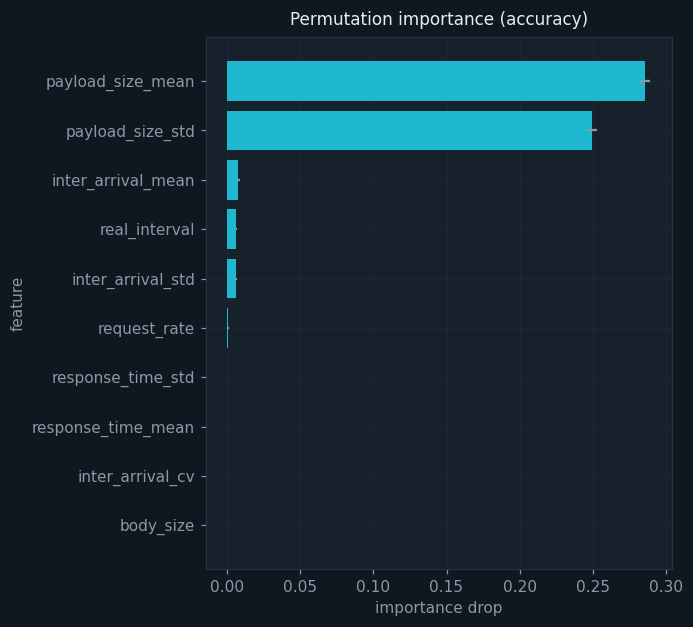

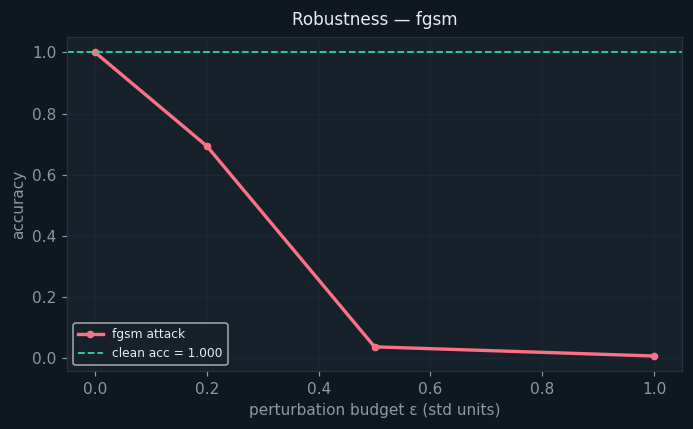

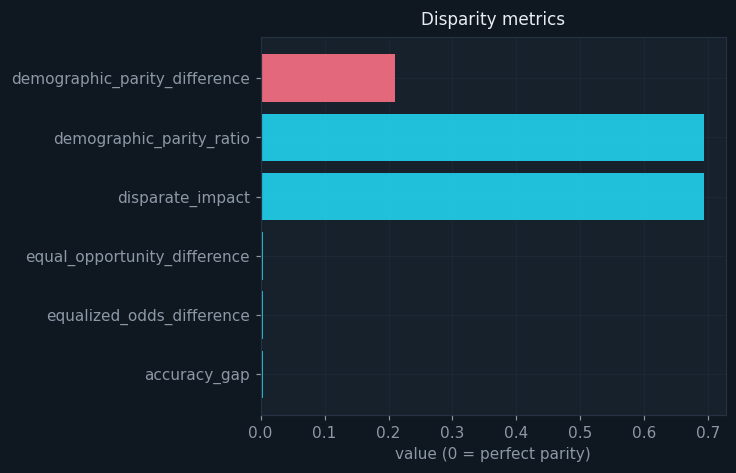

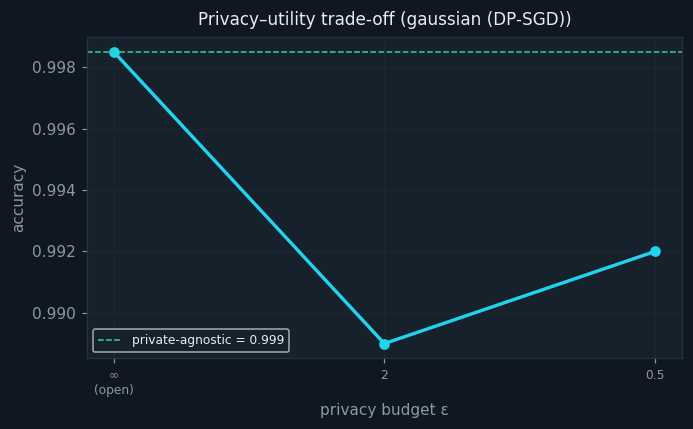

In [4]:
ds = build_dataset("cci_a1sd_binary", max_rows=12000, seed=42)
split = train_test_split_dataset(ds, test_size=0.3, seed=42, scale=True)
model = make_model("logistic", split.train.task, split.feature_names, split.train.class_names)
model.fit(split.X_train, split.y_train)

rng = np.random.default_rng(0)
bg = split.X_train[rng.choice(len(split.X_train), 100, replace=False)]

# EXPLAINABILITY
gi = EX.global_importance(model, split.X_test, split.y_test, n_repeats=5, seed=0)
# ROBUSTNESS
rc = RB.robustness_curve(model, split.X_test[:300], split.y_test[:300], "fgsm",
                         eps_range=(0.0,0.2,0.5,1.0))
# FAIRNESS
groups = split.test.group_values("policy_name")
fr = FA.analyze_fairness(model, split.X_test, split.y_test, groups, "policy_name",
                         task=split.train.task, positive_class=1, class_names=ds.class_names)
# PRIVACY
dp = PR.privacy_utility_curve(split.X_train[:2000], split.y_train[:2000],
                              split.X_test[:2000], split.y_test[:2000], split.train.task,
                              eps_range=(float("inf"),2.0,0.5), epochs=12, seed=0)

for f in (VZ.fig_permutation_importance(gi), VZ.fig_robustness_curve(rc),
          VZ.fig_fairness_metrics(fr), VZ.fig_dp_curve(dp)):
    display(f)

## Driving everything from one object

For a turnkey run use `TrustPipeline` — this is what the Qt **Run analysis** button calls on a background thread.

In [5]:
report = TrustPipeline("cci_a1sd_binary", "random_forest", PILLARS, quick=True).run()
print(report.headline())
print("pillars:", list(report.pillars))
print("figures per pillar:", {p: len(r.figures) for p, r in report.pillars.items()})

[cci_a1sd_binary] random_forest — accuracy=1.000
pillars: ['explainability', 'robustness', 'fairness', 'privacy']
figures per pillar: {'explainability': 6, 'robustness': 4, 'fairness': 2, 'privacy': 2}
